<img src="../img/viu_logo.png" width="200">

## 01MIAR - Actividad Dataset


### Introducción

Python es uno de los lenguajes de programación de referencia en el ámbito del tratamiento y análisis de datos. Existen diferentes funciones internas de Python y librerías que permiten mejorar la eficiencia de estos trabajos como es el caso de NumPy para el cálculo numérico y Pandas para operaciones con datos estructurados. Junto con estas operaciones, la visualización es un proceso importante para comprender mejor los datos. Con Matplotlib combinado con Pandas, y en el entorno Jupyter, es posible desarrollar y explicar el proceso de tratamiento y análisis de datos con gran facilidad.

### Objetivo

- Aplicar diferentes técnicas de tratamiento de datos explicadas durante el curso
- Explorar datos y evaluarlos mediante el uso de Pandas
- Aplicar adecuadamente técnicas de visualización
- Desarrollar una capacidad crítica y conocer fuentes de información

### Metodología

- Elegir un conjunto de datos para realizar el análisis y tratamiento de datos. Posibles fuentes de datos:
    - OpenData de ayuntamientos: Valencia, Madrid, Santander… 
    - https://archive.ics.uci.edu/datasets
    - https://www.kaggle.com/datasets
    - https://bigml.com/gallery/datasets
    - https://toolbox.google.com/datasetsearch
- Crear un notebook de Python que servirá como entrega de la actividad (se entregará el fichero .ipynb). En esta entrega se debe:
    - Referenciar adecuadamente la(s) fuente(s) de los datos. Si es pública, indicar cómo acceder a ella.
    - Describir los datos (tipos, cantidad, missing values, ...)
    - Crear una visualización preliminar de los datos (matplotlib o seaborn).
    - Plantear el objetivo principal del análisis y tratamiento de datos. ¿Buscas alguna correlación? ¿Quieres utilizarlos para entrenar un modelo? ¿Quieres limpiarlos? ¿Quieres balancearlos? ¿Quieres transformarlos? ¿Quieres realizar algún análisis estadístico? ¿Quieres unir varias fuentes en una única?.
    - Desarrollar con Python el procedimiento que hayas escogido para lograr tu objetivo principal.
    - Crear una visualización final donde se muestre el objetivo logrado (matplotlib o seaborn).
    - Concluir con un párrafo de reflexión. ¿Qué has aprendido?
- Se recomienda:
    - Formatear bien los apartados propuestos. Intercalar oportúnamente celdas Markdown y de código a lo largo de la entrega.
    - Mantener una estructura de código limpia, con comentarios oportunos y tomando en cuenta la secuencia en la que se ejecuta el código.
    - Utilizar un formato adecuado, si aplica, para referencias complementarias.
    - Utilizar visualizaciones en puntos intermedios del desarrollo solamente cuando sea necesario.
    - Formatear las visualizaciones para favorecer su interpretación a simple vista (tamaño, colores, leyendas, títulos, etiqutas, ...)
    - Sintetizar la información, aunque no hay límite de palabras.
    - Mantener una buena ortografía. 
  
**IMPORTANTE:**
- El uso de inteligencia artificial debe estar acorde a la normativa descrita en la guía docente.
- No está permitido compartir los resultados ni el código en ninguno de los foros.

### Evaluación
- Esta actividad corresponde con el 30% de la nota final de la asignatura

### Entrega
- Un solo documento en formato notebook: .ipynb. Si el dataset no se obtiene mediante descarga desde el propio notebook, adjuntarlo a la entrega como un archivo comprimido. Evitar compartir datos sensibles o confidenciales.
- Las entregas sólo serán validas si se realizan a través del site de la asignatura: Actividades, Actividad Final

### Fechas Límite
- Convocatoria 1 - 03/08/2026 - 08.00 CET
- Convocatoria 2 - 21/09/2026 - 08.00 CET

### Rúbrica

| Apartados | Criterio 1 | Criterio 2 | Criterio 3 |
| --------- | ---------- | ---------- | ---------- |
| Estilo (20%) | Redacción y ortografía | Formato correcto del notebook | Formato de las referencias |
| Visualizaciones (30%) | Formato e interpretabilidad | Descripción | Relevancia en el análisis |
| Datos (50%) | Análisis preliminar | Procedimiento | Análisis final |

---

## Desarrollo de la Actividad

---

## 1. Fuente de Datos

### Dataset: Netflix Movies & TV Shows

Catálogo completo del contenido disponible en Netflix hasta mediados de 2021: películas y series con metadatos de país, director, elenco, duración, clasificación por edad y géneros.

**Referencia:**
> Bansal, S. (2021). *Netflix Movies and TV Shows*. Kaggle.
> https://www.kaggle.com/datasets/shivamb/netflix-shows
> Licencia: CC0 1.0 Universal (Dominio Público)

**Cómo acceder:** el notebook descarga el dataset directamente desde Kaggle con `kagglehub`, que para datasets públicos no requiere credenciales ni token — solo conexión a internet. Si el CSV ya existe en el directorio local, se usa esa copia y se omite la descarga.

**Por qué Netflix?** La verdad es que no lo elegí por el contenido sino por los problemas que trae: texto libre, fechas en formato string, categorías, columnas multivalor (géneros y países separados por coma) y missing values con patrones distintos por columna. Es exactamente el tipo de dataset que obliga a usar el arsenal completo de pandas para limpiar y transformar antes de poder visualizar algo con sentido.


## 2. Instalación e Importación de Librerías

In [1]:
!pip install -q pandas numpy matplotlib seaborn
!pip install -qU kagglehub


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize': (14, 5), 'axes.titlesize': 14, 'axes.labelsize': 12})
sns.set_theme(style='whitegrid', palette='husl')
print('Librerías importadas correctamente')


Librerías importadas correctamente


## 3. Carga del Dataset

En simple: si el CSV ya está en el directorio, se carga directo; si no, se descarga desde Kaggle con `kagglehub`. Ojo: al ser un dataset público con licencia CC0, `kagglehub` lo descarga de forma anónima — no hace falta cuenta de Kaggle, ni token, ni configuración. El notebook corre de punta a punta en cualquier máquina con internet.


In [3]:
import os, shutil

if not os.path.exists('netflix_titles.csv'):
    import kagglehub
    ruta = kagglehub.dataset_download('shivamb/netflix-shows')
    shutil.copy(os.path.join(ruta, 'netflix_titles.csv'), 'netflix_titles.csv')

df_raw = pd.read_csv('netflix_titles.csv')
print(f'Dataset : {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas')
df_raw.head()


Dataset : 8,807 filas × 12 columnas


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 4. Descripción de los Datos

Antes de transformar nada, analizo la estructura bruta: tipos, dimensiones, duplicados y missing values. El punto clave es entender dónde están los problemas antes de tocar una sola fila — en un dataset con texto libre y fechas como string, ahí es donde aparecen.


In [4]:
print(f'Registros: {df_raw.shape[0]:,}  |  Columnas: {df_raw.shape[1]}')
df_raw.info()

Registros: 8,807  |  Columnas: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [5]:
# Duplicados: fila completa y por título + tipo
print(f"Duplicados (fila completa)   : {df_raw.duplicated().sum()}")
print(f"Duplicados (título + tipo)   : {df_raw.duplicated(subset=['title','type']).sum()}")

nulos = df_raw.isnull().sum()
pd.DataFrame({'Nulos': nulos, '%': (nulos / len(df_raw) * 100).round(2)}).query('Nulos > 0').sort_values('Nulos', ascending=False)


Duplicados (fila completa)   : 0


Duplicados (título + tipo)   : 0


,Nulos,%
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


In [6]:
# ─── Estadísticas descriptivas ────────────────────────────────────────────────
print('── Estadísticas descriptivas (columnas categóricas) ──')
df_raw.describe(include='object').T

── Estadísticas descriptivas (columnas categóricas) ──


,count,unique,top,freq
show_id,8807,8807,s1,1
type,8807,2,Movie,6131
title,8807,8807,Dick Johnson Is Dead,1
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,"January 1, 2020",109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


### Variables del dataset

| Variable | Tipo | Descripción |
|---|---|---|
| `show_id` | object | Identificador único del título |
| `type` | object | `Movie` o `TV Show` |
| `title` | object | Nombre del contenido |
| `director` | object | Director (~30% nulos) |
| `cast` | object | Elenco principal (~9% nulos) |
| `country` | object | País(es) de producción (~9% nulos) |
| `date_added` | object | Fecha de incorporación a Netflix (string) |
| `release_year` | int64 | Año de lanzamiento original |
| `rating` | object | Clasificación por edad (TV-MA, PG-13, etc.) |
| `duration` | object | Duración: minutos para películas, temporadas para series |
| `listed_in` | object | Géneros separados por coma |
| `description` | object | Sinopsis del contenido |

Tres columnas con nulls relevantes: `director` (~30%), `cast` y `country` (~9% cada una). La columna `duration` mezcla unidades distintas según el tipo de contenido — requiere extracción con regex. `listed_in` contiene múltiples géneros por registro — hay que explotarla para analizarla correctamente. Duplicados: cero, tanto a nivel de fila completa como por título + tipo — no hace falta deduplicar.


## 5. Visualización Preliminar

Sin tocar nada todavía. Quiero ver la distribución de tipos, el crecimiento del catálogo a lo largo del tiempo y cómo se distribuyen los ratings — para entender la forma general del dataset antes de limpiar.

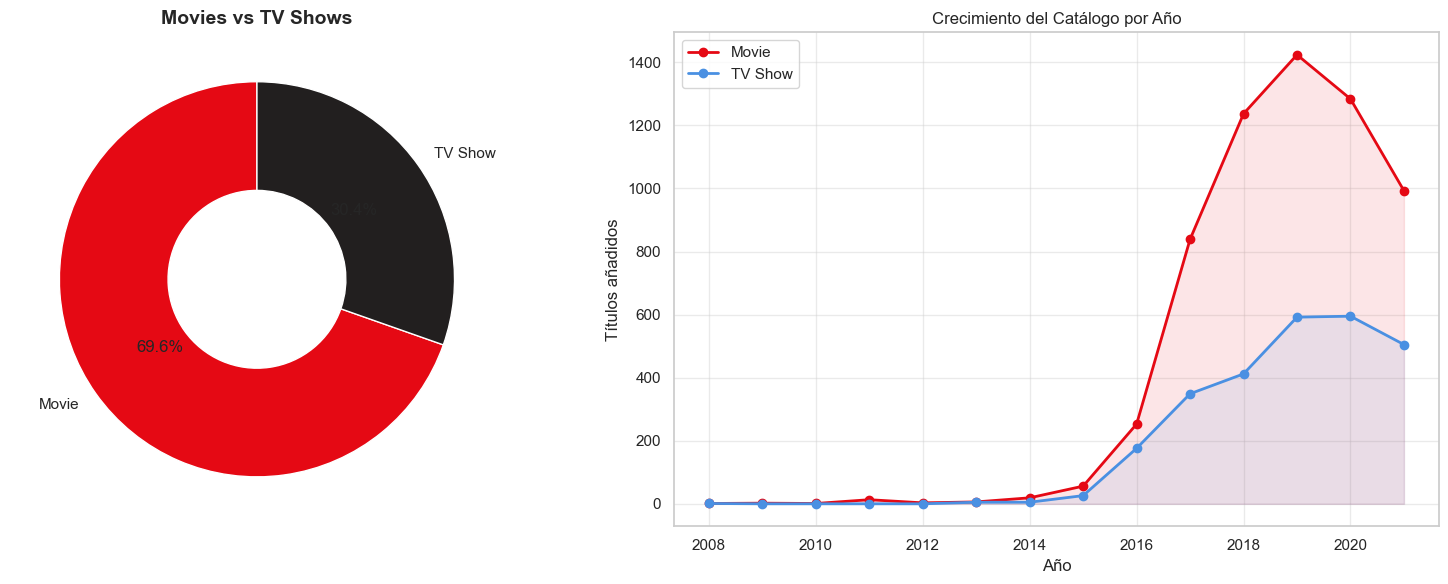

Figura 1: Distribución Movies/TV Shows y evolución del catálogo por año.


In [7]:
df_plot = df_raw.copy()
df_plot['add_year'] = pd.to_datetime(df_plot['date_added'].str.strip(), errors='coerce', format='mixed').dt.year

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Dona: Movies vs TV Shows
tipo = df_plot['type'].value_counts()
axes[0].pie(tipo.values, labels=tipo.index, autopct='%1.1f%%', startangle=90,
            colors=['#E50914','#221F1F'], wedgeprops=dict(width=0.55, edgecolor='white'))
axes[0].set_title('Movies vs TV Shows', fontsize=14, fontweight='bold')

# Líneas: crecimiento por año
anual = df_plot.groupby(['add_year','type']).size().unstack(fill_value=0)
anual = anual[(anual.index >= 2008) & (anual.index <= 2021)]
for t, c in zip(['Movie','TV Show'], ['#E50914','#4A90E2']):
    axes[1].plot(anual.index, anual[t], marker='o', color=c, linewidth=2, label=t)
    axes[1].fill_between(anual.index, anual[t], alpha=0.1, color=c)
axes[1].set(title='Crecimiento del Catálogo por Año', xlabel='Año', ylabel='Títulos añadidos')
axes[1].legend(); axes[1].grid(alpha=0.4)
axes[1].xaxis.set_major_locator(mticker.MultipleLocator(2))

plt.tight_layout(); plt.savefig('viz_preliminar_1.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 1: Distribución Movies/TV Shows y evolución del catálogo por año.')

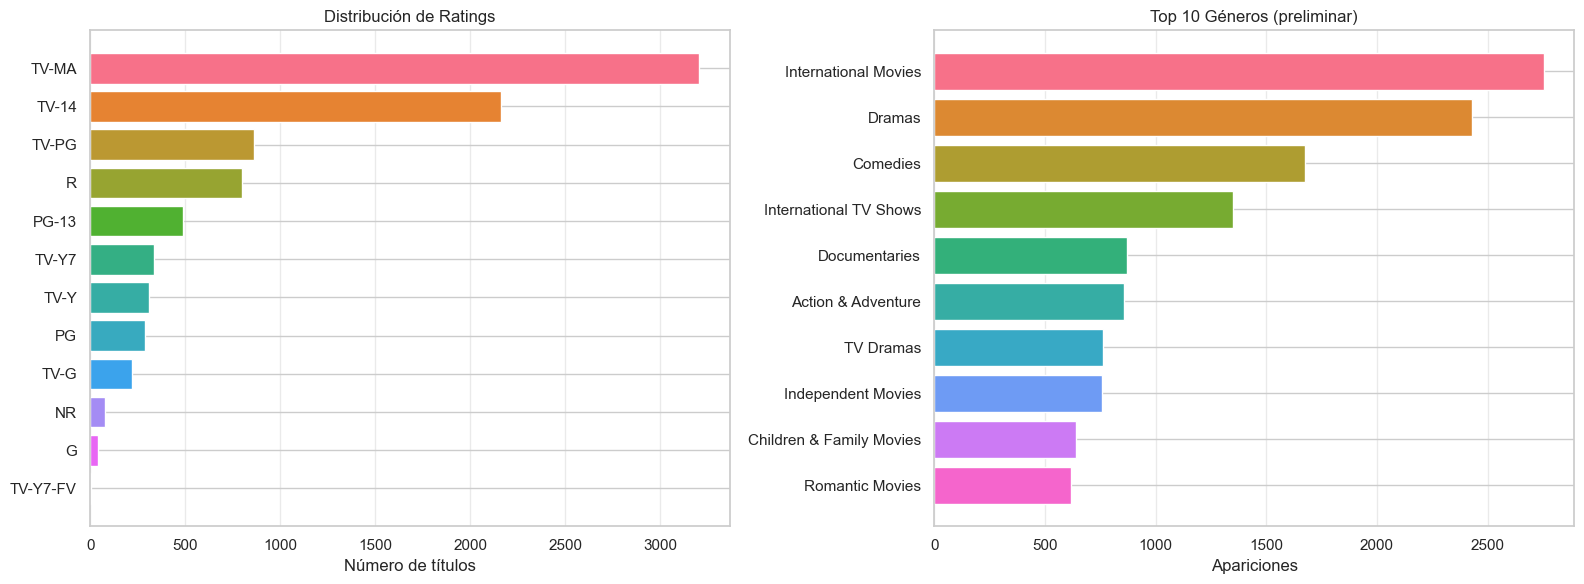

Figura 2: Distribución de ratings y top géneros.


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

rc = df_raw['rating'].value_counts().dropna().head(12)
axes[0].barh(rc.index[::-1], rc.values[::-1], color=sns.color_palette('husl', 12)[::-1], edgecolor='white')
axes[0].set(title='Distribución de Ratings', xlabel='Número de títulos'); axes[0].grid(axis='x', alpha=0.4)

gr = df_raw['listed_in'].str.split(', ').explode().str.strip().value_counts().head(10)
axes[1].barh(gr.index[::-1], gr.values[::-1], color=sns.color_palette('husl', 10)[::-1], edgecolor='white')
axes[1].set(title='Top 10 Géneros (preliminar)', xlabel='Apariciones'); axes[1].grid(axis='x', alpha=0.4)

plt.tight_layout(); plt.savefig('viz_preliminar_2.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 2: Distribución de ratings y top géneros.')

**Lo que veo a primera vista:**

- El catálogo es ~70% películas y ~30% series — Netflix apostó más volumen a contenido unitario.
- El crecimiento fue explosivo de 2016 a 2019 (de 429 a 2,016 títulos añadidos por año) y cae en 2020-2021. La lectura más razonable: el freno de producciones por COVID terminó reflejándose en menos adiciones al catálogo.
- Ojo con un matiz: en la caída post-2019 las series resistieron mejor que las películas — las adiciones de series bajan ~15% desde su pico mientras las de películas caen ~30%. Netflix protegió el formato serie.
- `TV-MA` (adultos) domina los ratings con diferencia — el contenido premium de Netflix apunta a audiencias adultas, no a familias.
- Los géneros más frecuentes mezclan Drama e International Movies en el top — hay un sesgo fuerte hacia contenido internacional que vale la pena explorar por país.


## 6. Objetivo del Análisis

**Pregunta central:**
> ¿Cómo está estructurado el catálogo de Netflix? ¿Qué patrones emergen en géneros, países, duración y clasificación?

En simple: no es un problema de predicción — es un análisis descriptivo/exploratorio completo. El catálogo de Netflix es una decisión editorial con lógica de negocio detrás: qué producen, dónde, para quién y en qué formato.

**Lo que voy a hacer — en orden:**

1. **Limpiar** — manejar nulos (`director`, `cast`, `country`), parsear `date_added` de string a datetime, estandarizar tipos
2. **Feature engineering** — extraer duración numérica de `duration` con regex, generar `add_year`/`add_month` desde la fecha
3. **Análisis de géneros** — explotar `listed_in` para contar géneros reales por título y por tipo de contenido
4. **Análisis por país** — identificar los principales productores de contenido en el catálogo
5. **Distribución de ratings** — cruzar clasificación por edad con tipo de contenido
6. **Visualización final** — gráficos que sinteticen cada hallazgo con claridad interpretativa

Con esto cubro: limpieza, transformación, extracción con regex, análisis categórico multivalor, estadística descriptiva y visualización completa.


## 7. Procedimiento

### 7.1 Limpieza de Datos

Trabajo sobre una copia del dataset original. La verdad es que no hay una receta única para los missing values — la decisión correcta depende del contexto de cada columna:

- `director`, `cast`, `country` → imputo `'Unknown'`. No saber quién dirigió un título no invalida el registro para análisis de tipo, género o fecha.
- `date_added`, `rating`, `duration` → elimino las filas (17 registros, 0.19% del total). Imputar fechas o ratings inventados distorsionaría las distribuciones más de lo que aporta conservar esas pocas filas.


In [9]:
df = df_raw.copy()

# Imputar metadatos opcionales con 'Unknown'
df[['director','cast','country']] = df[['director','cast','country']].fillna('Unknown')

# Eliminar filas sin fecha, rating o duración (< 1% del dataset)
n = len(df)
df = df.dropna(subset=['date_added','rating','duration'])
print(f'Filas eliminadas: {n - len(df)} | Restantes: {len(df):,}')

# Parsear fecha y estandarizar año
df['date_added']   = pd.to_datetime(df['date_added'].str.strip(), format='mixed')
df['release_year'] = df['release_year'].astype(int)
df[['title','type','date_added','rating','duration']].head(6)

Filas eliminadas: 17 | Restantes: 8,790


,title,type,date_added,rating,duration
0,Dick Johnson Is Dead,Movie,2021-09-25,PG-13,90 min
1,Blood & Water,TV Show,2021-09-24,TV-MA,2 Seasons
2,Ganglands,TV Show,2021-09-24,TV-MA,1 Season
3,Jailbirds New Orleans,TV Show,2021-09-24,TV-MA,1 Season
4,Kota Factory,TV Show,2021-09-24,TV-MA,2 Seasons
5,Midnight Mass,TV Show,2021-09-24,TV-MA,1 Season


### 7.2 Feature Engineering

Ahí está el truco de este dataset: `duration` mezcla formatos completamente distintos según el tipo — `"90 min"` para películas y `"2 Seasons"` para series. Hay que separar el número de la unidad con regex para poder operar sobre duraciones de forma numérica.

Además, descompongo `date_added` en año y mes para analizar estacionalidad en las incorporaciones al catálogo.


In [10]:
# Extraer número y unidad de 'duration' con regex
df['duration_val']  = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_unit'] = df['duration'].str.extract(r'\d+\s+(.+)').squeeze().str.replace(r'^Season$','Seasons',regex=True)

# Año y mes de incorporación al catálogo
df['add_year']  = df['date_added'].dt.year
df['add_month'] = df['date_added'].dt.month

df[['title','type','duration','duration_val','duration_unit','add_year','add_month']].head(8)

,title,type,duration,duration_val,duration_unit,add_year,add_month
0,Dick Johnson Is Dead,Movie,90 min,90.0,min,2021,9
1,Blood & Water,TV Show,2 Seasons,2.0,Seasons,2021,9
2,Ganglands,TV Show,1 Season,1.0,Seasons,2021,9
3,Jailbirds New Orleans,TV Show,1 Season,1.0,Seasons,2021,9
4,Kota Factory,TV Show,2 Seasons,2.0,Seasons,2021,9
5,Midnight Mass,TV Show,1 Season,1.0,Seasons,2021,9
6,My Little Pony: A New Generation,Movie,91 min,91.0,min,2021,9
7,Sankofa,Movie,125 min,125.0,min,2021,9


### 7.3 Análisis de Géneros

La columna `listed_in` contiene géneros separados por coma — un título puede tener entre 1 y 3 géneros asignados. Para contar géneros reales necesito explotar la columna: convertir cada lista en filas individuales antes de agregar.

In [11]:
# Explotar géneros (uno por fila) y contar top 15
top_genres = df['listed_in'].str.split(', ').explode().str.strip().value_counts().head(15)

# Tabla: géneros por tipo de contenido
df_genres = (df[['type','listed_in']]
             .assign(genre=df['listed_in'].str.split(', '))
             .explode('genre'))
df_genres['genre'] = df_genres['genre'].str.strip()

genre_tipo = df_genres.groupby(['genre','type']).size().unstack(fill_value=0)
genre_tipo['Total'] = genre_tipo.sum(axis=1)
genre_tipo.sort_values('Total', ascending=False).head(15)

type,Movie,TV Show,Total
genre,,,
International Movies,2752,0,2752
Dramas,2426,0,2426
Comedies,1674,0,1674
International TV Shows,0,1349,1349
Documentaries,869,0,869
Action & Adventure,859,0,859
TV Dramas,0,762,762
Independent Movies,756,0,756
Children & Family Movies,641,0,641


### 7.4 Análisis por País

`country` también puede contener múltiples valores separados por coma — coproduciones internacionales. Aplico la misma lógica de explosión para contar la contribución real de cada país al catálogo.

In [12]:
# Explotar países (excluir 'Unknown')
df_paises = (df[df['country'] != 'Unknown'][['country','type']]
             .assign(pais=lambda x: x['country'].str.split(', '))
             .explode('pais'))
df_paises['pais'] = df_paises['pais'].str.strip()

top_paises = df_paises['pais'].value_counts().head(10)

pais_tipo = df_paises.groupby(['pais','type']).size().unstack(fill_value=0)
pais_tipo['Total'] = pais_tipo.sum(axis=1)
pais_tipo.sort_values('Total', ascending=False).head(10)

type,Movie,TV Show,Total
pais,,,
United States,2748,932,3680
India,962,84,1046
United Kingdom,532,271,803
Canada,319,126,445
France,303,90,393
Japan,119,197,316
Spain,171,61,232
South Korea,61,170,231
Germany,182,44,226


### 7.5 Duración y Distribución de Ratings

Separo el análisis de duración por tipo: para películas me interesa la distribución de minutos, para series el número de temporadas. Los ratings los cruzo con el tipo para detectar diferencias editoriales entre ambos formatos.

In [13]:
print('── Películas (minutos) ──')
print(df[df['type']=='Movie']['duration_val'].describe().round(1).to_string())

print('\n── TV Shows (temporadas) ──')
print(df[df['type']=='TV Show']['duration_val'].describe().round(1).to_string())

# Tabla ratings × tipo (se reutiliza en la viz final)
rating_pivot = df.groupby(['rating','type']).size().unstack(fill_value=0)
rating_pivot['Total'] = rating_pivot.sum(axis=1)
rating_pivot.sort_values('Total', ascending=False)

── Películas (minutos) ──
count    6126.0
mean       99.6
std        28.3
min         3.0
25%        87.0
50%        98.0
75%       114.0
max       312.0

── TV Shows (temporadas) ──
count    2664.0
mean        1.8
std         1.6
min         1.0
25%         1.0
50%         1.0
75%         2.0
max        17.0


type,Movie,TV Show,Total
rating,,,
TV-MA,2062,1143,3205
TV-14,1427,730,2157
TV-PG,540,321,861
R,797,2,799
PG-13,490,0,490
TV-Y7,139,194,333
TV-Y,131,175,306
PG,287,0,287
TV-G,126,94,220


## 8. Visualización Final

Cuatro figuras que sintetizan los hallazgos del análisis: distribución geográfica, géneros por tipo, duración y clasificación de edad, y estacionalidad del catálogo. Cada una responde a una dimensión distinta del contenido Netflix.

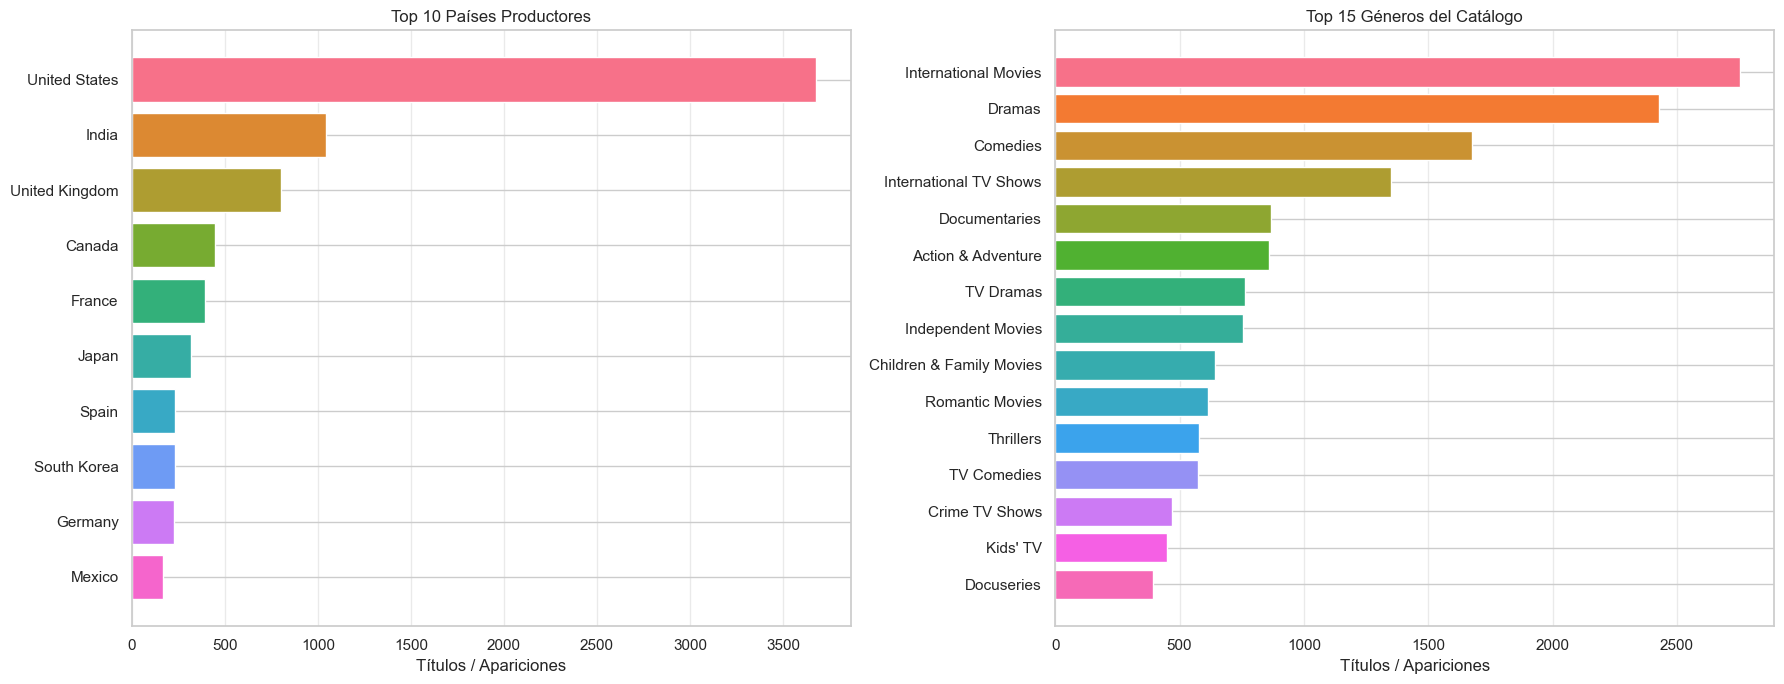

Figura 3: Top 10 países y top 15 géneros.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, data, title in [(axes[0], top_paises, 'Top 10 Países Productores'),
                         (axes[1], top_genres, 'Top 15 Géneros del Catálogo')]:
    ax.barh(data.index[::-1], data.values[::-1],
            color=sns.color_palette('husl', len(data))[::-1], edgecolor='white')
    ax.set(title=title, xlabel='Títulos / Apariciones')
    ax.grid(axis='x', alpha=0.4)

plt.tight_layout(); plt.savefig('viz_final_1_paises_generos.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 3: Top 10 países y top 15 géneros.')

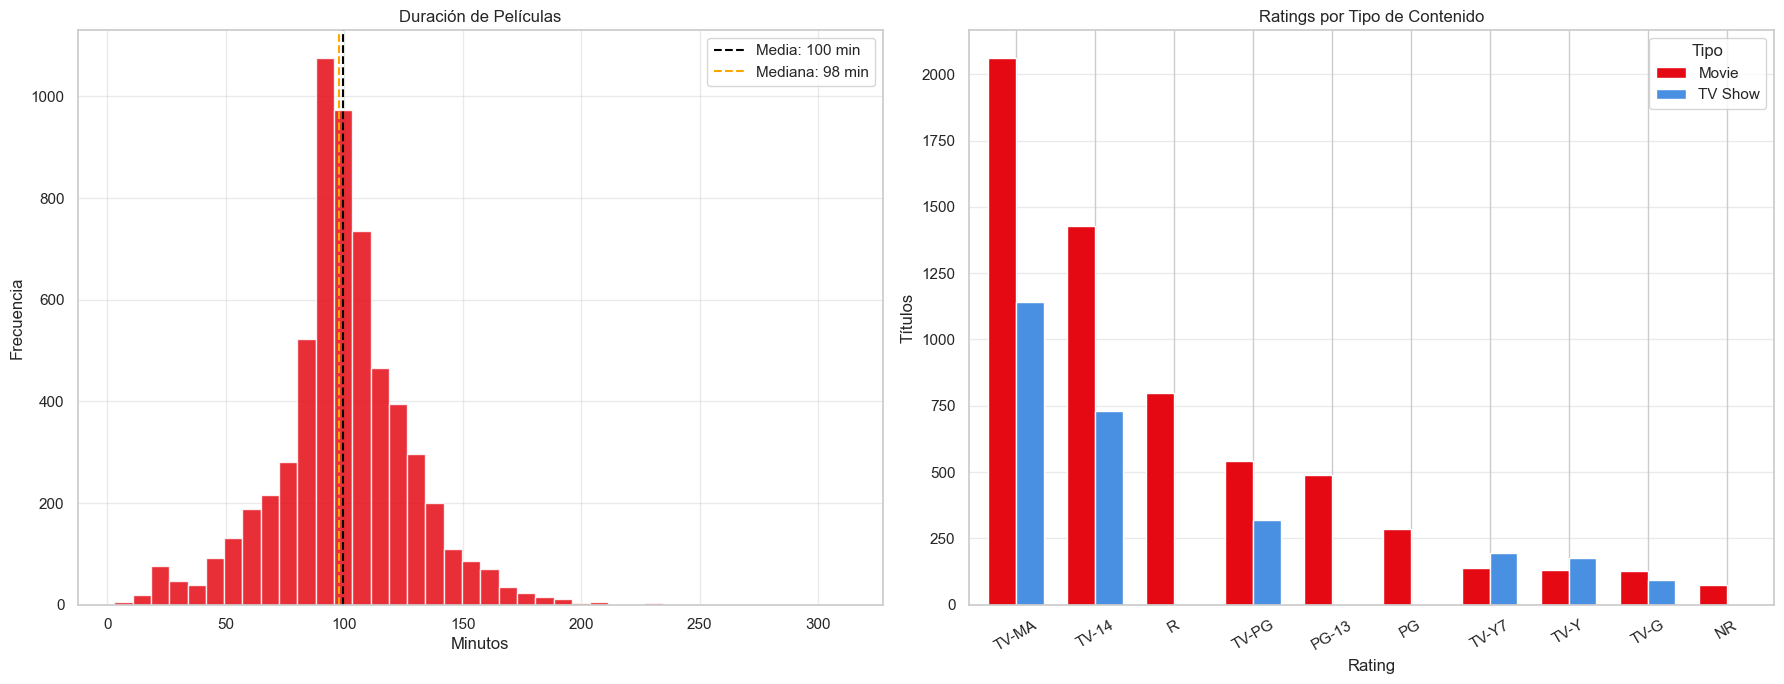

Figura 4: Duración de películas y distribución de ratings.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Duración de películas
mins = df[df['type']=='Movie']['duration_val'].dropna()
axes[0].hist(mins, bins=40, color='#E50914', edgecolor='white', alpha=0.85)
axes[0].axvline(mins.mean(),   color='black',  linestyle='--', label=f'Media: {mins.mean():.0f} min')
axes[0].axvline(mins.median(), color='orange', linestyle='--', label=f'Mediana: {mins.median():.0f} min')
axes[0].set(title='Duración de Películas', xlabel='Minutos', ylabel='Frecuencia')
axes[0].legend(); axes[0].grid(alpha=0.4)

# Ratings por tipo
rp = rating_pivot[rating_pivot['Total'] >= 50].drop(columns='Total')
rp = rp.sort_values(rp.columns[0], ascending=False)
rp.plot(kind='bar', ax=axes[1], color=['#E50914','#4A90E2'], edgecolor='white', width=0.7)
axes[1].set(title='Ratings por Tipo de Contenido', xlabel='Rating', ylabel='Títulos')
axes[1].legend(title='Tipo'); axes[1].tick_params(axis='x', rotation=30); axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout(); plt.savefig('viz_final_2_duracion_rating.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 4: Duración de películas y distribución de ratings.')

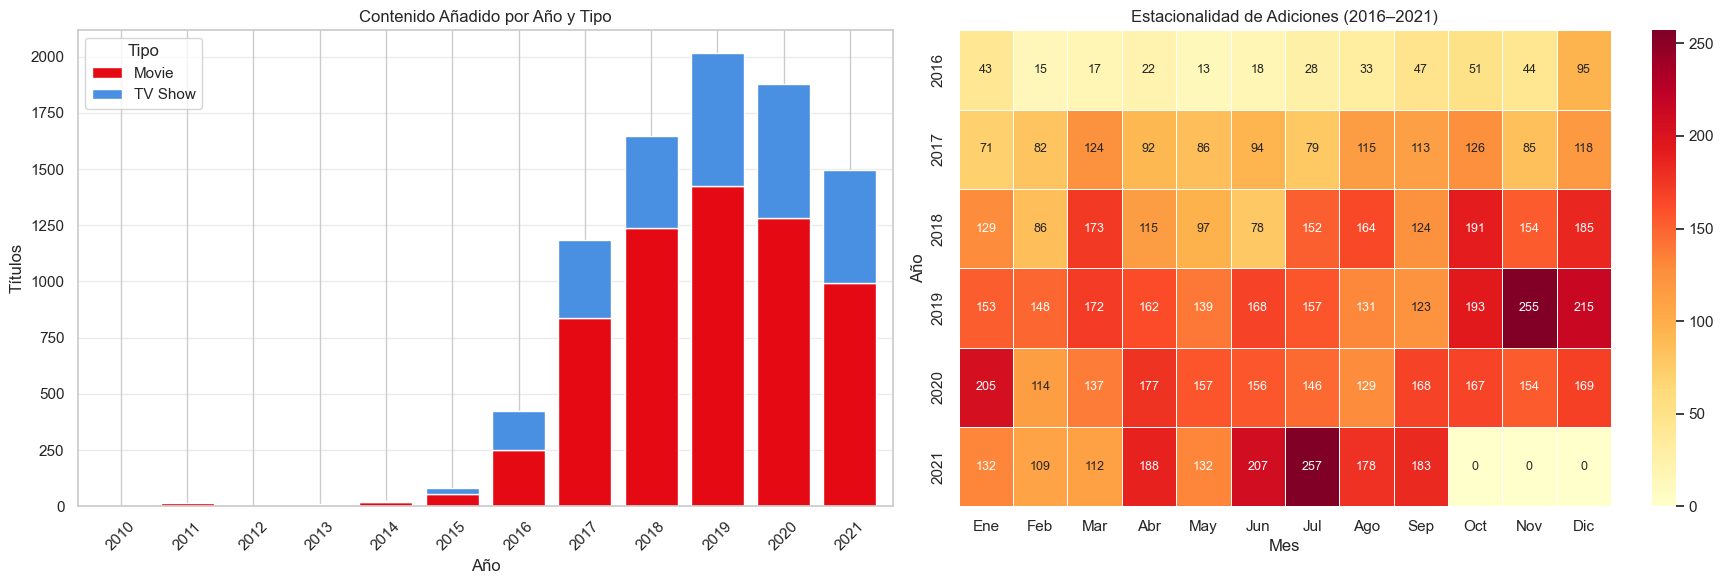

Figura 5: Crecimiento anual y estacionalidad mensual.


In [16]:
anual = df.groupby(['add_year','type']).size().unstack(fill_value=0)
anual = anual[(anual.index >= 2010) & (anual.index <= 2021)]

heat = df.groupby(['add_year','add_month']).size().unstack(fill_value=0)
heat = heat[(heat.index >= 2016) & (heat.index <= 2021)]
heat.columns = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

anual.plot(kind='bar', stacked=True, ax=axes[0], color=['#E50914','#4A90E2'], edgecolor='white', width=0.8)
axes[0].set(title='Contenido Añadido por Año y Tipo', xlabel='Año', ylabel='Títulos')
axes[0].legend(title='Tipo'); axes[0].tick_params(axis='x', rotation=45); axes[0].grid(axis='y', alpha=0.4)

sns.heatmap(heat, ax=axes[1], cmap='YlOrRd', annot=True, fmt='d', linewidths=0.5, annot_kws={'size':9})
axes[1].set(title='Estacionalidad de Adiciones (2016–2021)', xlabel='Mes', ylabel='Año')

plt.tight_layout(); plt.savefig('viz_final_3_crecimiento_estacionalidad.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 5: Crecimiento anual y estacionalidad mensual.')

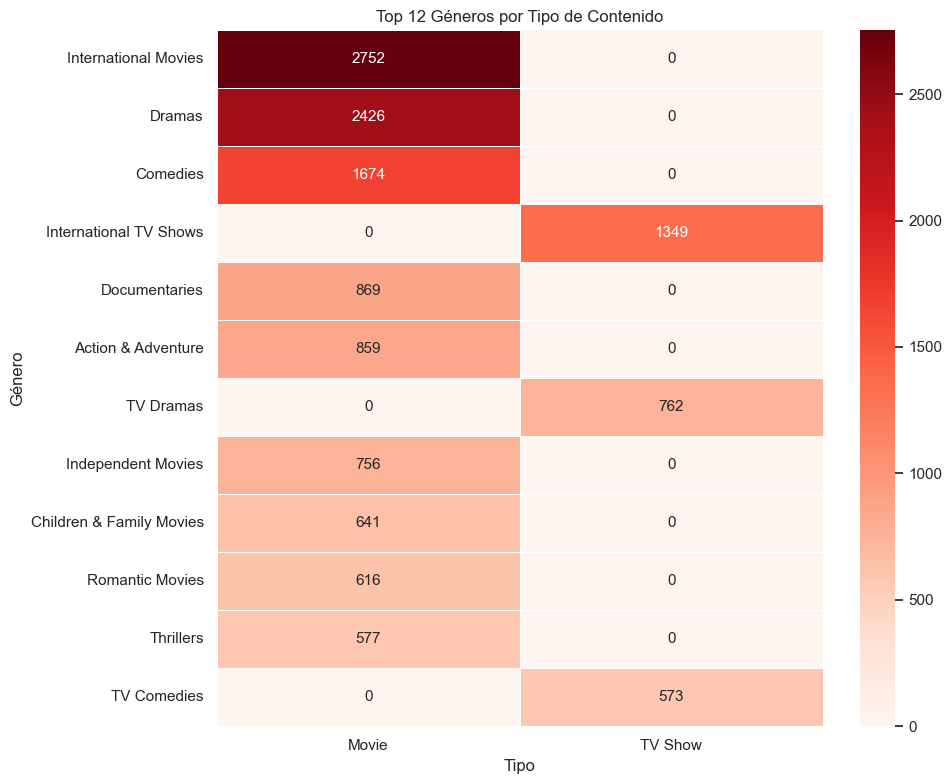

Figura 6: Géneros principales por tipo de contenido.


In [17]:
matrix = (df_genres[df_genres['genre'].isin(top_genres.head(12).index)]
          .groupby(['genre','type']).size().unstack(fill_value=0)
          .loc[top_genres.head(12).index])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matrix, ax=ax, cmap='Reds', annot=True, fmt='d', linewidths=0.5, annot_kws={'size':11})
ax.set(title='Top 12 Géneros por Tipo de Contenido', xlabel='Tipo', ylabel='Género')
plt.tight_layout(); plt.savefig('viz_final_4_generos_tipo.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figura 6: Géneros principales por tipo de contenido.')

**Hallazgos principales:**

- **Estados Unidos domina** la producción con más del triple que el segundo país: 3,680 títulos vs 1,046 de India. Dicho esto, el contenido internacional pesa cada vez más — "International Movies" es el género más frecuente del catálogo, señal de una estrategia deliberada de expansión global.
- **Las películas viven del Drama y lo internacional** como géneros primarios; las series se concentran en International TV Shows y TV Dramas, con Crime TV Shows y Kids' TV como nichos fuertes — audiencias y formatos distintos con estrategias editoriales diferenciadas.
- **La duración típica de una película en Netflix es ~99 minutos** (media 99.6, mediana 98) — ligeramente por encima del estándar de 90 min, con cola derecha de documentales y películas largas.
- **`TV-MA` es el rating dominante en ambos formatos** — Netflix apuesta por contenido adulto maduro como producto estrella, con muy poco peso en clasificaciones para niños.
- **La estacionalidad existe**: julio, diciembre y septiembre concentran más adiciones (819, 782 y 758 títulos entre 2016 y 2021) — alineado con vacaciones de verano en EEUU, cierre de año y arranque de la temporada de otoño.
- **2019 fue el pico de incorporaciones** (2,016 títulos). La caída de 2020-2021 es consistente con el freno de producciones por COVID.


## 9. Reflexión

Lo que más me llamó la atención de este dataset no fue el contenido en sí, sino los problemas estructurales que generan las columnas multivalor. `listed_in` y `country` almacenan listas como strings — un diseño que funciona para presentar información en una tabla, pero que hace imposible agregar directamente. El proceso de explotar esas columnas con `str.split().explode()` es exactamente el tipo de transformación que en un pipeline de producción tendría que estar automatizado para que el análisis pueda escalar a cientos de miles de registros.

El manejo de nulos requirió criterio, no solo pandas. Para `director` la imputación con `'Unknown'` es correcta — no saber quién dirigió una película no invalida el registro para análisis de tipo, género o fecha. Para `date_added` y `rating` con menos del 1% de nulos, eliminar las filas fue más limpio que imputar con valores que podrían distorsionar los gráficos de distribución temporal.

La extracción de duración numérica con regex fue directa, pero evidenció un problema de diseño original: mezclar películas y series en la misma columna `duration` con unidades distintas. En un esquema relacional bien diseñado serían tablas separadas. Ese tipo de decisiones tiene un costo directo en el análisis posterior — y es un error que se comete más de lo que parece en datasets reales.

El catálogo de Netflix resultó ser un espejo de su estrategia de negocio: contenido adulto primario, foco en producción estadounidense con expansión internacional controlada, pico de adiciones en 2019 antes de que COVID frenara las producciones. Los datos no mienten — pero hay que saber limpiarlos, transformarlos y leerlos.

## Referencias

1. Bansal, S. (2021). *Netflix Movies and TV Shows*. Kaggle.
   https://www.kaggle.com/datasets/shivamb/netflix-shows
   Licencia: CC0 1.0 Universal (Dominio Público)

2. McKinney, W. (2022). *Python for Data Analysis* (3.ª ed.). O'Reilly Media.

3. The pandas development team. (2023). *pandas documentation*.
   https://pandas.pydata.org/docs/

4. Waskom, M. (2021). Seaborn: Statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.
   https://doi.org/10.21105/joss.03021

5. Kaggle. (2024). *kagglehub — Python client documentation*.
   https://github.com/Kaggle/kagglehub
